In [39]:
# This cell imports the Python libraries required for the entire EEG analysis workflow. NumPy
# supports matrix operations, time sample selection, normalization, averaging, and pseudoinverse
# calculations. MNE reads BrainVision recordings, manages channel metadata, extracts annotated
# events, and renders electrode topographies. Matplotlib displays both the event related
# potential waveforms and the continuous projected signal. Pandas remains available for optional
# tabular inspection, although the main computation uses NumPy arrays. Runtime warnings are
# suppressed to keep notebook output readable, matching the previous workflow. Install missing
# dependencies before running this cell, and execute the imports before defining functions or
# loading any EEG recording data.

import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [40]:
# This cell centralizes run parameters so the analysis can be configured without editing function
# bodies. Choose the BrainVision input file and optional frequency cutoffs first. Epoch durations
# and baseline limits are expressed in milliseconds relative to each event, while trigger spacing
# is measured in samples. The erp_time setting identifies the center of the requested scalp
# response. The erp_around setting specifies a symmetric averaging radius from zero to five
# milliseconds; zero means use only the nearest sampled instant. Normalization affects the
# resulting A vector and pseudoinverse W. Figure options control colors and saving. Actual
# sampling frequency comes from the recording header. Set view_min and view_max to the
# same numerical bounds for both A and W maps. When left as None, shared limits are calculated
# automatically from both vectors; set explicit numbers to impose a fixed common scale.

eeg_file = "Smits11.vhdr"
low_freq = 1.0
high_freq = None

# Recording frequency: populated from raw.info after loading, never hard-coded
sfreq = None

# Epoch and baseline windows, in milliseconds relative to the event
epoch_pre_ms = 20
epoch_post_ms = 100
baseline_start_ms = 11
baseline_end_ms = 14
min_trigger_distance = 100  # samples; preserve original strict > comparison

# Selected scalp map: one time point only, in milliseconds
erp_time = 18.0
erp_around = 3.0          # milliseconds, allowed range [0, 5]
normalize_erp = True

# Figure settings
n_cols = 1                 # retained configuration; single-map mode only
cmap = "jet"
view_min = None             # shared color-scale minimum; None = automatic
view_max = None             # shared color-scale maximum; None = automatic
save_figures = True
plot_all_topographies = False  # retained configuration; grid plotting is disabled

In [41]:
# This function opens a BrainVision EEG recording with data loaded into memory for subsequent
# processing. It checks the available channel names and assigns appropriate auxiliary channel
# types to recognized hand movement, ECG, and pressure signals. Optional lower and upper
# frequency cutoffs are applied through the MNE filtering interface when either cutoff is
# provided. After filtering, the function retains EEG channels and excludes the separately
# classified auxiliary channels. The returned MNE Raw object supplies signal samples, event
# annotations, electrode names, channel metadata, and the actual recording sampling frequency.
# Subsequent functions use this object rather than assuming a fixed number of electrodes.

def read_prep_eeg(eeg_file_path_vhdr, low_freq=None, high_freq=None):
    """Load BrainVision data, classify auxiliary channels and retain EEG channels."""
    raw = mne.io.read_raw_brainvision(eeg_file_path_vhdr, preload=True)
    auxiliary_types = {"Mano DX": "misc", "Mano SX": "misc", "ECG": "ecg", "pressione": "misc"}
    raw.set_channel_types({name: kind for name, kind in auxiliary_types.items() if name in raw.ch_names})
    if low_freq is not None or high_freq is not None:
        raw = raw.copy().filter(l_freq=low_freq, h_freq=high_freq)
    return raw.pick("eeg")

In [42]:
# This function builds the event related potential from the EEG recording by aligning data
# segments with annotated events. It reads sampling frequency from the recording, converts the
# configured pre event and post event durations to sample counts, and discards triggers occurring
# too close to a previously accepted trigger. Events lacking a complete surrounding epoch are
# skipped. Remaining epochs are stacked and averaged across trials, producing one waveform for
# each EEG channel. The configured baseline interval is then averaged separately for each channel
# and subtracted from that channel's waveform. The function returns the baseline corrected ERP
# matrix and its event relative time axis.

def get_erp(raw, epoch_pre_ms, epoch_post_ms, baseline_start_ms,
            baseline_end_ms, min_trigger_distance):
    """Average event-aligned EEG epochs and remove the original post-trigger baseline."""
    sfreq = float(raw.info["sfreq"])
    pre = int((epoch_pre_ms / 1000.0) * sfreq)
    post = int((epoch_post_ms / 1000.0) * sfreq)
    if pre < 0 or post <= 0:
        raise ValueError("Epoch durations must satisfy pre >= 0 and post > 0.")

    events, _ = mne.events_from_annotations(raw)
    if len(events) == 0:
        raise ValueError("No annotated events found in the EEG recording.")
    samples = events[:, 0]
    clean = [samples[0]]
    for sample in samples[1:]:
        if sample - clean[-1] > min_trigger_distance:
            clean.append(sample)

    epochs = []
    for trigger in clean:
        if trigger - pre < 0 or trigger + post > raw.n_times:
            continue
        epoch, _ = raw[:, trigger - pre:trigger + post]
        epochs.append(epoch)
    if not epochs:
        raise ValueError("No complete epochs remain after trigger filtering.")

    erp = np.mean(np.stack(epochs, axis=0), axis=0)
    b_start = pre + int((baseline_start_ms / 1000.0) * sfreq)
    b_end = pre + int((baseline_end_ms / 1000.0) * sfreq)
    if not (0 <= b_start < b_end <= erp.shape[1]):
        raise ValueError("Baseline interval must lie inside the ERP epoch.")
    baseline = np.mean(erp[:, b_start:b_end], axis=1, keepdims=True)
    time_epoch = np.arange(-pre, post) / sfreq
    return erp - baseline, time_epoch

In [43]:
# This function constructs the spatial ERP vector A without plotting any figure. It interprets
# erp_time as a center in milliseconds and validates that erp_around lies between zero and five
# milliseconds. When the radius equals zero, the nearest recorded ERP sample is selected,
# reproducing the earlier single instant behavior. Otherwise, all recorded time samples within
# the inclusive symmetric interval around the requested center are selected and averaged for
# every EEG channel. Optional normalization divides the resulting vector by its sum, preserving
# the original convention. The function returns A, its unnormalized counterpart, the nearest
# actual center time, and selected sample indices.

def compute_A(erp_mean, time_epoch, erp_time, erp_around=0.0, normalize=True):
    """Select the time neighborhood, average each electrode, and optionally normalize."""
    if not (np.isfinite(erp_around) and 0.0 <= erp_around <= 5.0):
        raise ValueError("erp_around must be between 0 and 5 milliseconds, inclusive.")
    if not np.isfinite(erp_time):
        raise ValueError("erp_time must be a finite number of milliseconds.")
    time_epoch = np.asarray(time_epoch, dtype=float)
    erp_mean = np.asarray(erp_mean, dtype=float)
    if time_epoch.ndim != 1 or time_epoch.size == 0:
        raise ValueError("time_epoch must contain at least one time sample.")
    if erp_mean.ndim != 2 or erp_mean.shape[1] != time_epoch.size:
        raise ValueError("ERP columns and time_epoch samples must match.")
    target_s = erp_time / 1000.0
    if target_s < time_epoch[0] or target_s > time_epoch[-1]:
        raise ValueError(f"erp_time={erp_time} ms is outside the epoch time range.")
    closest_index = int(np.argmin(np.abs(time_epoch - target_s)))
    actual_time_ms = float(time_epoch[closest_index] * 1000.0)
    if erp_around == 0:
        selected_indices = np.array([closest_index], dtype=int)
    else:
        radius_s = erp_around / 1000.0
        # Include both boundaries when they coincide with sampled times.
        tolerance_s = max(1e-12, np.finfo(float).eps * max(1.0, abs(target_s)) * 10)
        selected_indices = np.flatnonzero(
            (time_epoch >= target_s - radius_s - tolerance_s) &
            (time_epoch <= target_s + radius_s + tolerance_s)
        )
        if not selected_indices.size:
            raise ValueError("No recorded ERP samples fall inside the requested time window.")
    # Average across selected time samples, retaining one mean per EEG channel.
    potential = erp_mean[:, selected_indices].mean(axis=1)
    if normalize:
        denominator = potential.sum()
        if np.isclose(denominator, 0.0, atol=1e-15, rtol=0):
            raise ValueError("Cannot normalize A: ERP electrode values sum to (nearly) zero.")
        A = potential / denominator
    else:
        A = potential.copy()
    return A, potential, actual_time_ms, selected_indices


In [44]:
# This function converts the previously computed spatial ERP vector A into its Moore Penrose
# pseudoinverse W. The input is flattened to a single row vector so the linear algebra operation
# has an unambiguous orientation. An all zero vector is rejected because it does not provide
# informative spatial weights for the downstream projection. NumPy computes the pseudoinverse,
# which is then flattened to one coefficient per retained EEG channel. W is calculated solely
# from A, including any configured temporal averaging or normalization already performed
# upstream. No topographic image is created here; numerical computation remains separate from
# plotting and data presentation.

def compute_W(A):
    """Compute Moore-Penrose pseudoinverse of a single topographic row vector."""
    A = np.asarray(A, dtype=float).reshape(-1)
    if not np.any(A):
        raise ValueError("Cannot compute useful W from an all-zero A vector.")
    return np.linalg.pinv(A.reshape(1, -1)).reshape(-1)

In [45]:
# This function plots one scalp topography from a supplied vector of electrode values, without
# recomputing ERP data, A, or W. It copies EEG channel metadata from the loaded recording and
# checks that the vector length matches the selected EEG channel count. A standard ten twenty
# montage provides approximate sensor positions; missing positions follow the configured MNE
# handling. The topographic field is interpolated and displayed with the requested color map, a
# labeled title, and an accompanying color scale. The figure can optionally be saved as a high
# resolution image. Both figure and axes are returned for inspection or later customization.
# The shared view_min and view_max limits control the numeric color scale, so maps using different
# input vectors can be compared on identical bounds. The limits affect visualization only.

def plot_topography(raw, values, time_ms, title_prefix="A", cmap="jet",
                    save_path=None, dpi=300, view_min=None, view_max=None):
    """Plot exactly one 2D scalp map; do not calculate or normalize its values."""
    values = np.asarray(values, dtype=float).reshape(-1)
    info = raw.info.copy()
    picks = mne.pick_types(info, eeg=True)
    info = mne.pick_info(info, picks)
    if values.size != len(info.ch_names):
        raise ValueError(f"Map has {values.size} values but EEG has {len(info.ch_names)} channels.")
    montage = mne.channels.make_standard_montage("standard_1020")
    info.set_montage(montage, on_missing="ignore")

    if view_min is not None and view_max is not None and view_min >= view_max:
        raise ValueError("view_min must be smaller than view_max.")
    fig, ax = plt.subplots(figsize=(6, 5))
    im, _ = mne.viz.plot_topomap(
        values, info, axes=ax, show=False, cmap=cmap,
        vlim=(view_min, view_max)
    )
    ax.set_title(f"{title_prefix} - {time_ms:.1f} ms")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    plt.show()
    return fig, ax

In [46]:
# This cell checks that the notebook is configured to render exactly one topography at a time,
# rather than the earlier grid of many ERP instants. It then opens the configured BrainVision
# recording using the preprocessing function and applies the requested filtering settings. The
# actual sampling frequency is retrieved directly from the loaded recording metadata, not
# assigned a hard coded value. The number of retained EEG channels and the measured frequency are
# printed for verification. These metadata determine epoch sample counts and later signal time
# axes. The loaded Raw object is reused throughout the ERP calculation, spatial mapping, and
# projection stages.

if plot_all_topographies or n_cols != 1:
    raise ValueError("This notebook is configured for exactly one topography; use plot_all_topographies=False and n_cols=1.")
raw = read_prep_eeg(eeg_file, low_freq=low_freq, high_freq=high_freq)
sfreq = float(raw.info["sfreq"])
print(f"EEG sampling frequency: {sfreq:g} Hz")
print(f"EEG channels: {len(raw.ch_names)}")

Extracting parameters from Smits11.vhdr...
Setting channel info structure...
Reading 0 ... 1524799  =      0.000 ...   304.960 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 16501 samples (3.300 s)

EEG sampling frequency: 5000 Hz
EEG channels: 63


In [47]:
# This cell computes the trial averaged ERP waveform using the prepared EEG recording and the
# centrally defined epoch, baseline, and trigger settings. The get_erp function excludes closely
# spaced annotated triggers, ignores incomplete epochs at recording boundaries, aligns valid
# segments to their stimulus events, and averages across the accepted trials. A baseline mean is
# removed separately from each EEG channel. The resulting two dimensional matrix has channels
# along rows and event relative samples along columns. The accompanying time vector is derived
# from the actual recording frequency. Matrix dimensions and temporal limits are printed so that
# later ERP time selections can be checked.

erp_mean, time_epoch = get_erp(
    raw, epoch_pre_ms, epoch_post_ms, baseline_start_ms,
    baseline_end_ms, min_trigger_distance
)
print("ERP matrix shape:", erp_mean.shape)
print("ERP time range (ms):", time_epoch[0] * 1000, "to", time_epoch[-1] * 1000)

Used Annotations descriptions: [np.str_('Response/R  7'), np.str_('Response/R 15')]
ERP matrix shape: (63, 600)
ERP time range (ms): -20.0 to 99.8


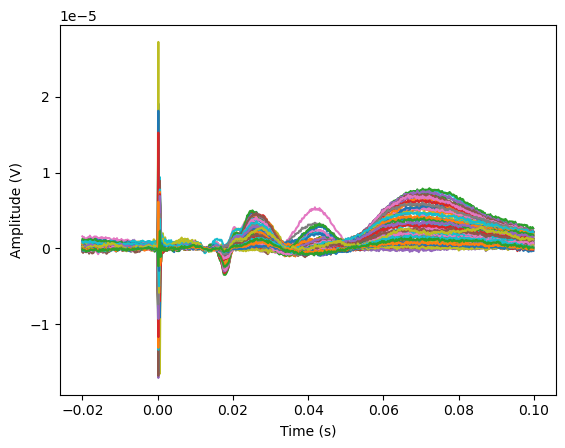

In [48]:
# This cell visualizes the complete baseline corrected ERP time course for each retained EEG
# channel. It iterates over the channel dimension of the ERP matrix and plots one waveform
# against the shared event relative time axis. The horizontal axis is measured in seconds, while
# the vertical axis shows electrical amplitude in volts. These curves help inspect event aligned
# responses, relative timing, and variation across sensors before selecting a specific
# topographic response. Unlike the later scalp maps, this figure summarizes temporal waveforms
# rather than spatial patterns. The cell does not modify the ERP matrix, select an averaging
# window, or compute pseudoinverse weights.

for i in range(erp_mean.shape[0]):
    plt.plot(time_epoch, erp_mean[i])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.show()

In [49]:
# This cell computes the spatial vector A from the previously averaged ERP matrix using the
# configured time center and symmetric neighborhood radius. A zero radius selects the nearest
# recorded sample, while positive radii include all samples within erp_time minus erp_around
# through erp_time plus erp_around. Each channel is averaged across the chosen samples to yield
# one potential per electrode. Optional sum normalization follows the existing notebook
# convention. The cell also records the selected indices and reports the requested interval,
# actual sampled interval, sample count, and resulting vector size. It performs no plotting,
# leaving subsequent display operations independent.

A, A_raw, actual_erp_time, selected_erp_indices = compute_A(
    erp_mean, time_epoch, erp_time, erp_around=erp_around, normalize=normalize_erp
)
print(f"ERP center: {erp_time:.3f} ms; nearest acquired sample: {actual_erp_time:.3f} ms")
print(f"ERP averaging window: [{erp_time-erp_around:.3f}, {erp_time+erp_around:.3f}] ms")
print(f"ERP samples averaged: {len(selected_erp_indices)}")
print(f"Actual time span: {time_epoch[selected_erp_indices[0]]*1000:.3f} to "
      f"{time_epoch[selected_erp_indices[-1]]*1000:.3f} ms")
print("A shape:", A.shape)


ERP center: 18.000 ms; nearest acquired sample: 18.000 ms
ERP averaging window: [15.000, 21.000] ms
ERP samples averaged: 31
Actual time span: 15.000 to 21.000 ms
A shape: (63,)


In [50]:
# This cell derives the spatial coefficient vector W from the already calculated A vector. The
# computation calls the dedicated pseudoinverse helper rather than including matrix algebra
# directly in a plotting routine. A is treated as a single row across EEG channels, and its Moore
# Penrose pseudoinverse is returned as one coefficient per channel. Consequently, changing
# erp_time, erp_around, or normalization upstream changes the numerical vector used here. The
# resulting W is used both to display a corresponding scalp topography and to project the
# complete filtered EEG recording into FSResult. This cell reports the weight vector dimensions
# for verification.

W = compute_W(A)
print("W shape:", W.shape)

W shape: (63,)


In [51]:
# This cell prints the numerical values of the two spatial vectors for direct inspection before
# rendering any scalp map. A contains one mean event related potential per EEG channel at the
# selected time neighborhood, optionally normalized by the sum across channels. W contains the
# pseudoinverse coefficients calculated from that exact A vector. Printing both arrays makes it
# possible to inspect magnitudes, signs, and ordering, and provides a basic check that both
# vectors have compatible channel dimensions. The cell does not repeat ERP extraction, temporal
# averaging, or pseudoinverse calculations. Its sole purpose is to expose already computed
# results for review. This cell also determines one shared color range across both
# A and W, using their combined minimum and maximum unless explicit view limits are provided.
# These limits do not change any scientific data, normalization, or subsequent calculations.

print("A:", A)
print("W:", W)

# Resolve a single shared color scale for the A and W topographies.
if view_min is not None and not np.isfinite(view_min):
    raise ValueError("view_min must be finite or None.")
if view_max is not None and not np.isfinite(view_max):
    raise ValueError("view_max must be finite or None.")
shared_values = np.concatenate((np.asarray(A, dtype=float).ravel(),
                                np.asarray(W, dtype=float).ravel()))
if not np.all(np.isfinite(shared_values)):
    raise ValueError("A and W must contain only finite values for plotting.")
effective_view_min = float(np.min(shared_values)) if view_min is None else float(view_min)
effective_view_max = float(np.max(shared_values)) if view_max is None else float(view_max)
if effective_view_min >= effective_view_max:
    raise ValueError("Shared color range requires view_min < view_max.")
print(f"Common A/W color scale: [{effective_view_min:.6g}, {effective_view_max:.6g}]")

A: [-0.01045719 -0.03985299 -0.01854798 -0.05463521 -0.03358393 -0.04561273
 -0.04718237  0.01387894 -0.08127614  0.09081699  0.09363394  0.12306588
  0.13101428  0.02119232  0.00663648 -0.03820755 -0.05318441  0.05933458
 -0.04715925 -0.15715335  0.02059198  0.09801283  0.05707721  0.04888623
 -0.05654662 -0.01586712  0.02892682  0.03935741  0.01923904 -0.01358512
  0.0011263  -0.01424277  0.00058536  0.01023682 -0.02973936 -0.03150049
  0.01171394 -0.08012394  0.00951505  0.00477619  0.04106832 -0.00515046
  0.10166317  0.13377551  0.09892985  0.03998083  0.09929739  0.09790701
  0.04774233 -0.04214975  0.00521096  0.08987879  0.11205355  0.06008775
 -0.04734186  0.02416807  0.06668187  0.03457683 -0.02671879  0.00887892
  0.02292687  0.01309566  0.0022771 ]
W: [-0.04511329 -0.17192959 -0.08001776 -0.23570148 -0.14488426 -0.19677768
 -0.20354922  0.05987508 -0.35063302  0.39179313  0.40394572  0.5309179
  0.56520806  0.09142568  0.02863039 -0.16483099 -0.2294426   0.25597502
 -0.2034

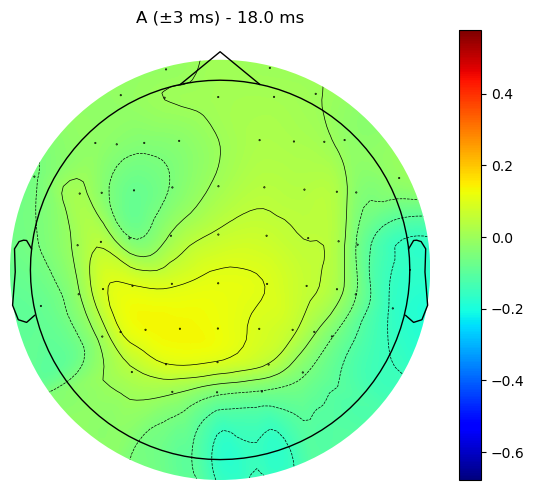

In [52]:
# This cell displays a single scalp map of the computed spatial ERP vector A. All numerical
# preparation has already been completed by compute_A, including selection of the requested
# center time, optional averaging across the symmetric interval, and any requested sum
# normalization. The plotting helper receives A and the actual nearest recorded center time and
# draws one interpolated topography over the EEG electrode positions. When erp_around is
# positive, the title records the averaging radius so the map cannot be mistaken for an
# instantaneous sample. The configured color map controls presentation. Optional image saving
# writes A.png without changing the underlying vector. The same effective_view_min and
# effective_view_max values are applied to both A and W so colors represent equal numerical
# values in the two figures. These parameters do not alter the computed data.

fig_A, ax_A = plot_topography(raw, A, actual_erp_time, title_prefix=f"A (±{erp_around:g} ms)" if erp_around else "A", cmap=cmap,
                              save_path="A.png" if save_figures else None,
                              view_min=effective_view_min, view_max=effective_view_max)

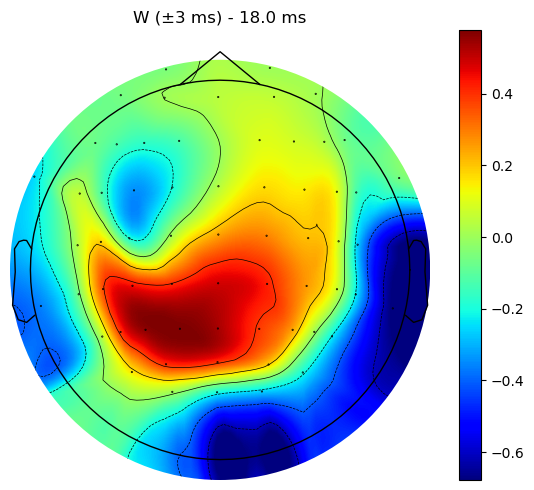

In [53]:
# This cell displays the spatial weights W as one scalp topography using the same center time and
# averaging radius as the A map. W was calculated earlier from the exact A vector, so no
# additional sampling, averaging, normalization, or pseudoinverse calculation occurs during
# visualization. The plotting function checks vector length against EEG metadata and interpolates
# one value per channel over the standard electrode montage. The chosen color map and color bar
# help inspect relative spatial coefficients. When temporal averaging is active, the title
# identifies the radius. If saving is enabled, the figure is written to W.png. The underlying W
# array remains unchanged. The common plotting limits effective_view_min and
# effective_view_max guarantee that the W color scale exactly matches A, even when their
# numerical amplitudes differ substantially. Values outside explicit limits are clipped
# visually but never changed in the underlying vector.

fig_W, ax_W = plot_topography(raw, W, actual_erp_time, title_prefix=f"W (±{erp_around:g} ms)" if erp_around else "W", cmap=cmap,
                              save_path="W.png" if save_figures else None,
                              view_min=effective_view_min, view_max=effective_view_max)

In [54]:
# This cell applies the computed spatial weight vector W to the complete preprocessed EEG
# recording to construct FSResult. It first loads the channel by sample data matrix from the MNE
# Raw object and checks that its channel count matches the number of coefficients in W. Matrix
# multiplication then combines the simultaneous electrode signals using the fixed weights derived
# from the selected ERP neighborhood. The output is a one dimensional time series spanning the
# full recording rather than only the short ERP epoch. Shapes of the input vector, recording
# matrix, and resulting signal are printed for verification. The calculation is independent of
# scalp plotting.

eeg_data = raw.get_data()
if W.size != eeg_data.shape[0]:
    raise ValueError("W and the EEG data must have the same number of channels.")
FSResult = W @ eeg_data
print("Dimensions W:", W.shape)
print("Dimensions EEG:", eeg_data.shape)
print("Dimensions FSResult:", FSResult.shape)

Dimensions W: (63,)
Dimensions EEG: (63, 1524800)
Dimensions FSResult: (1524800,)


In [55]:
# This cell presents the already computed FSResult array directly as notebook output. FSResult is
# a continuous, one dimensional signal created by multiplying the spatial coefficient vector W by
# the entire filtered EEG channel matrix. Its sample count matches the number of time samples in
# the original recording, not the number of samples selected around erp_time. Displaying the
# array can help verify numerical output and inspect representative values before plotting the
# entire trace. The calculation itself took place in the previous cell and is not repeated here.
# No data transformation, normalization, temporal selection, or figure generation is performed.

FSResult

array([-8.24866767e-18, -2.41480992e-05, -2.07745824e-05, ...,
        4.48723011e-07,  1.58016817e-05, -3.72482482e-18])

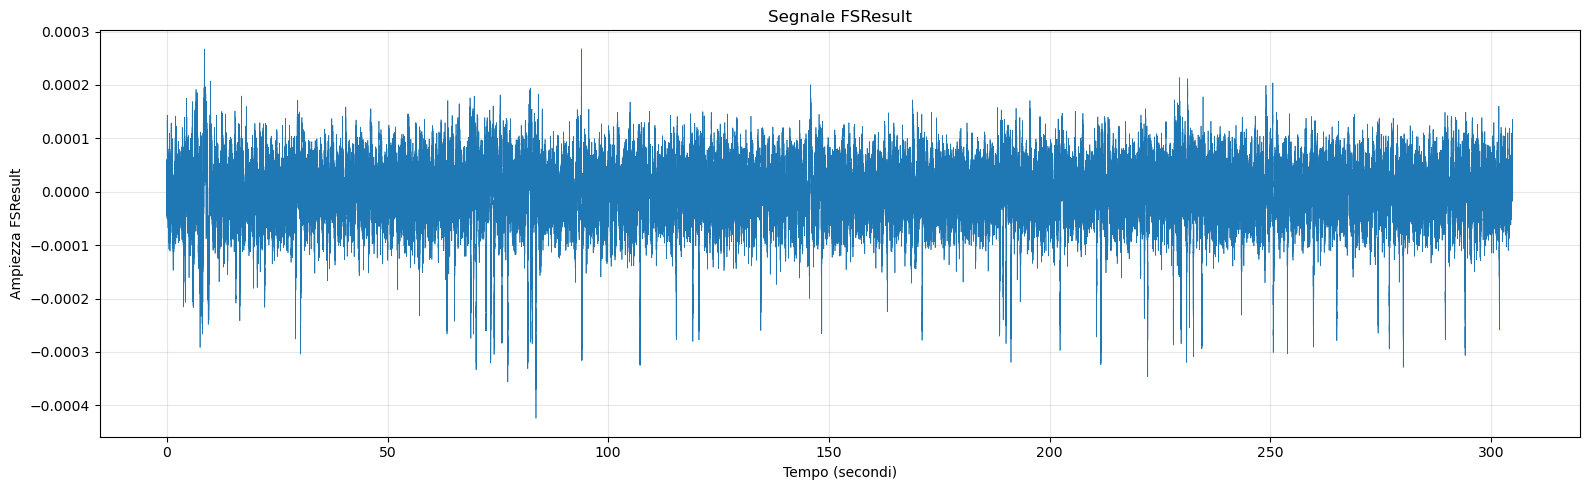

In [56]:
# This cell plots the continuous FSResult time series obtained by applying spatial weights W to
# the complete filtered EEG recording. The horizontal axis is calculated from the sample indices
# and the actual sampling frequency retrieved from the BrainVision metadata. Each projected
# sample is shown in acquisition order, producing a full recording trace rather than a short
# event related waveform or a scalp topography. Figure dimensions, line width, labels, and grid
# are chosen for readable inspection. The plotted values are not reprocessed in this cell. Any
# change to erp_time or erp_around affects this trace indirectly through the updated spatial
# weights W.

time = np.arange(FSResult.size) / sfreq
plt.figure(figsize=(16, 5))
plt.plot(time, FSResult, linewidth=0.5)
plt.title("Segnale FSResult")
plt.xlabel("Tempo (secondi)")
plt.ylabel("Ampiezza FSResult")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# This cell compares the spatial ERP vector A with its Moore Penrose pseudoinverse vector W after
# both have been computed from the selected time neighborhood. It subtracts their coefficients
# channel by channel and reports the resulting difference vector. A Euclidean norm summarizes the
# overall numerical distance between the two vectors. This comparison is sensitive to scaling and
# normalization, even though the pseudoinverse of a nonzero row vector preserves its relative
# spatial pattern. The cell does not establish statistical significance or measure biological
# similarity. It retains the notebook's original numerical diagnostic while reflecting any
# configured temporal averaging around erp_time.

diff_A_W = A - W
distanza = np.linalg.norm(diff_A_W)
print("Differenza elemento per elemento:", diff_A_W)
print("Distanza euclidea:", distanza)

Differenza elemento per elemento: [ 0.03465611  0.1320766   0.06146978  0.18106627  0.11130033  0.15116494
  0.15636685 -0.04599614  0.26935687 -0.30097614 -0.31031178 -0.40785202
 -0.43419378 -0.07023336 -0.02199391  0.12662344  0.17625819 -0.19664044
  0.15629024  0.52082116 -0.06824378 -0.32482383 -0.18915929 -0.16201361
  0.18740088  0.05258515 -0.09586623 -0.1304342  -0.06376     0.04502238
 -0.00373268  0.04720189 -0.00193995 -0.0339258   0.09855906  0.10439561
 -0.0388211   0.26553835 -0.03153377 -0.01582876 -0.13610433  0.01706912
 -0.33692141 -0.44334477 -0.32786293 -0.13250026 -0.32908101 -0.32447316
 -0.15822262  0.13968829 -0.01726963 -0.29786685 -0.37135613 -0.19913653
  0.15689543 -0.08009528 -0.22099005 -0.11459091  0.0885486  -0.02942558
 -0.07598182 -0.04340026 -0.00754652]
Distanza euclidea: 1.5955856115340632
